# Our Original CNN Model

This Jupyter Notebook contains our original `convolutional neural network (CNN)` model used for image recognition. The model is trained to recognize four different types of dinnerware items from images. The model is created using the `Keras` library with `TesnsorFlow` as the backend. 

`Matplotlib.pyplot` and `NumPy` libraries are used for formatting and visualising data and performance results. `Time` library provides a method for measuring the model's training time. The `Scikit Learn` library is used to calculate performance metrics and also to display them more visually.

In [1]:
import os, shutil, pathlib
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import time

keras.utils.set_random_seed(2)

Using the `keras.utils.set_random_seed` function reduces the difference between different runs so that performance results are more similar if the model is created and trained again. 

## Data Preprocessing

The dataset used for the training contains images of four different types of dinnerware items: bowls, drinking glasses, mugs and plates. The images were preprocessed using Python wiht function from the `Pillow (PIL)` library. The images were cropped, resized, converted to RGB and renamed with code. For a more detailed description of the dataset refer to the `Assignment2_raport.ipynb` notebook.

The dataset is fetched from the base folder using the `pathlib.Path` class and Keras library's `image_dataset_from_directory` function. For the function to work correctly the dinnerware images need to be divided in their own folders with aproriate class names. The function is used three times to get subsets for training, validation and testing. The `batch_size` is 32 and `image_size` is 224x224 pixels. The `seed` parameter ensures that the initial shuffle of the datasets is always the same increasing reproducbility.

In [2]:
base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

image_size = (224, 224)
batch_size = 32
seed = 123

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = image_size,
    batch_size = batch_size,
    seed = seed,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


The training set has 296 images, the validation set has 93 images and the test set has 95 images. A batch has 32 images wiht 224 x 224 dimension and they are RGB colour images that contain three colour channels. This explains the batch shape: (32, 224, 224, 3).

Below are some examples of the images in the training dataset with their labels or class names.

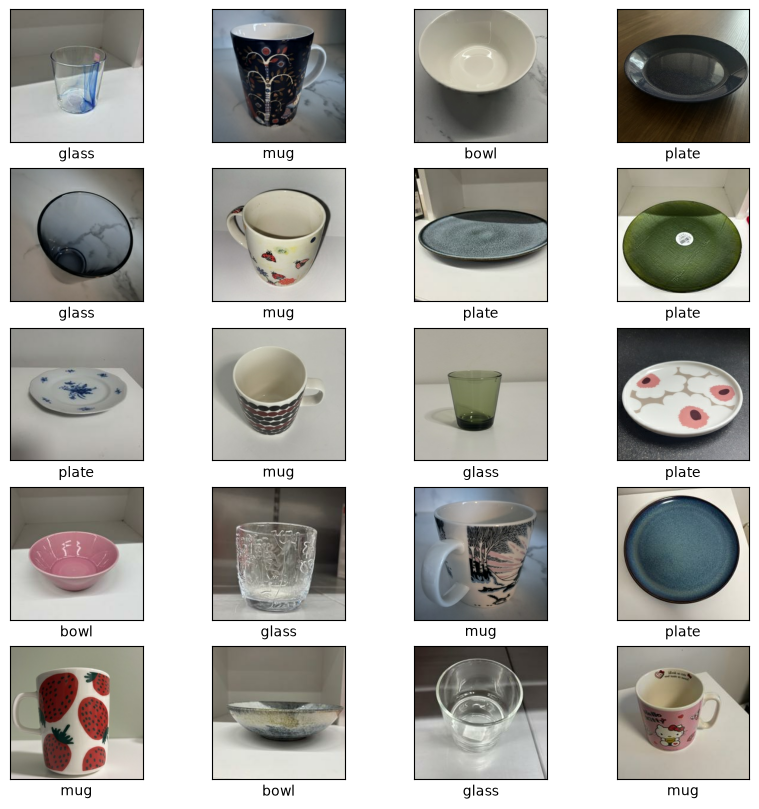

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modeling (1. Sandra)

The model has 17 layers, as shown in the `model.summary()` output. Most of them are `Conv2D` and `MaxPooling2D` layers, which are the core building blocks of a CNN model. A `Conv2D` layer slides a small 3x3 window over the image and looks for patterns, such as edges and shapes. The model is trained to learn which patterns are useful for telling the classes apart. A `MaxPooling2D` layer slides a 2x2 window over the feature map and keeps only the maximum value from each window, which halves the output shape height and width.

Before the convolutional layers, the `Rescaling` layer scales the pixel values from 0–255 to 0–1, and the `BatchNormalization` layer normalises the input. At the end, the `Flatten` layer turns the feature map into a one-dimensional vector and `Dropout(0.2)` reduces overfitting.

In [4]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1)
    ]
)

model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    layers.Conv2D(32, kernel_size=3, activation="relu"),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 3)    │            12 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        12,804 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,488 (630.81 KB)

 Trainable params: 161,482 (630.79 KB)

 Non-trainable params: 6 (24.00 B)

The model has 161,488 parameters in total, of which 161,482 are trainable and 6 are non-trainable.

The model has a data augmentation layer. During training it flips, rotates, zooms and changes the contrast of the images, so the model sees a slightly different version of each image in every epoch. This helps reduce overfitting, which is important because the dataset is small.

The plots below show nine augmented versions of the same training image.

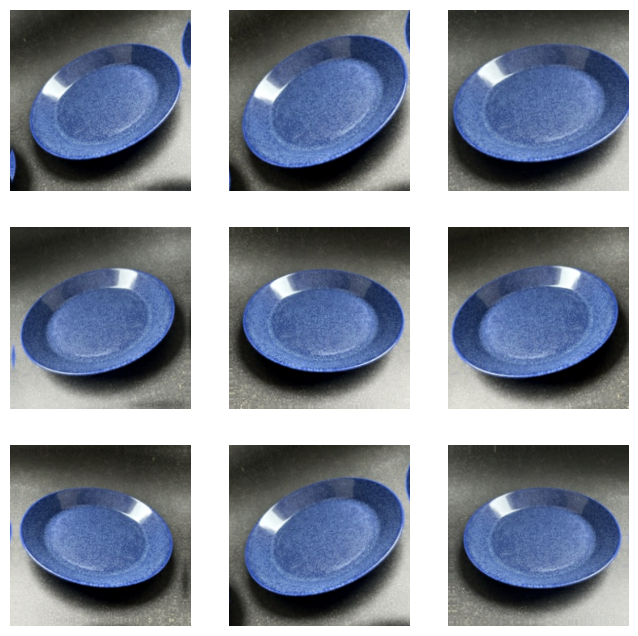

In [5]:
for images, labels in train_dataset.take(1):
    img = images[0:1]

plt.figure(figsize=(8, 8))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(keras.ops.convert_to_numpy(aug[0]).astype("uint8"))
    plt.axis("off")
plt.show()

## Compile and train the model (2. Anni)

In [6]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

In [7]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=7, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset, 
    batch_size=128,
    epochs=70, 
    validation_data=validation_dataset, 
    callbacks=callbacks
)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/70


/opt/anaconda3/envs/keras/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 504ms/step - accuracy: 0.2568 - loss: 1.3896 - val_accuracy: 0.1613 - val_loss: 1.3892
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 505ms/step - accuracy: 0.3243 - loss: 1.3718 - val_accuracy: 0.2473 - val_loss: 1.3875
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 499ms/step - accuracy: 0.3581 - loss: 1.3608 - val_accuracy: 0.2796 - val_loss: 1.3852
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 512ms/step - accuracy: 0.3784 - loss: 1.3424 - val_accuracy: 0.3226 - val_loss: 1.3825
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 522ms/step - accuracy: 0.4561 - loss: 1.3086 - val_accuracy: 0.2688 - val_loss: 1.3775
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 523ms/step - accuracy: 0.4730 - loss: 1.2767 - val_accuracy: 0.3011 - val_loss: 1.3724
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 522ms/step - accuracy: 0.4797 - loss: 1.2222 - val_accuracy: 0.4194 - val_loss: 1.3600
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 529ms/step - accuracy: 0.4696 - loss: 1.1917 - val_accuracy: 0.4301 - val_

## Learning Curves (3. Nur)

The plots show the training and validation loss and accuracy for each epoch, using the `history` object from `model.fit`. The curves show how the model learns and helps to identify whether the model is overfitting.

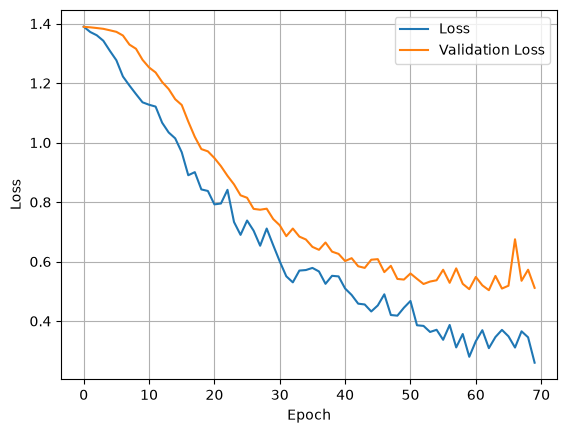

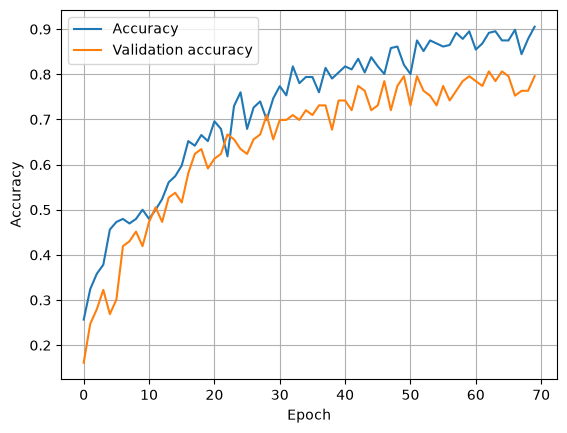

In [8]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

Both loss curves start at about 1.4 and decrease. Around epoch 50 the validation loss levels off and starts to fluctuate more, while the training loss keeps decreasing more slowly. The gap between both curves widens slightly towards the end, which shows that the model starts to overfit mildly.

The accuracy curves show the same pattern. Both curves increase, but they are not smooth and fluctuate slightly. Training accuracy is clearly higher than the validataion accuracy. It rises from about 25% to about 90%, while validation accuracy rises from about 15% to about 80%. After about epoch 40 the growth slows down and the validation accuracy levels off between 70% and 80%. 

For the validation result, the best model saved by ModelCheckpoint is loaded from the file and evaluated with the validation dataset. The validation set was used to choose the best epoch and the best version.

In [9]:
val_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
val_loss, val_acc = val_model.evaluate(validation_dataset)

print(f"Validation accuracy: {val_acc:.3f}")
print(f"Validation loss: {val_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - accuracy: 0.8065 - loss: 0.5037
Validation accuracy: 0.806
Validation loss: 0.504


Validation accuracy is 0.806 and validation loss is 0.504, which matches epoch 63 in the training log.

## Version Tests

The table below shows the validation results for some of the tested models. Not all tested configurations are documented here. Validation scores were recorded from the epoch with the lowest validation loss. The test set was not used when selecting the final model. Version 4 was selected based on its overall validation performance.

Other things were tested: Dropout with different values (0.1-0.5), augmentation strength(0.1 and 0.2), different Conv2D parameters, an additional Conv2D and MaxPooling2D layer, BatchNormalization, and learning rate (0.0001, 0.001, 0.00001). These changes were first tested one at a time, while the below table combines them together at once.

|Test|Modification|Validation accuracy (%)|Validation loss|Training time (s)|Conclusion|
|---|---|---|---|---|---|
|Original model|-|72.0|0.851|51.9|Baseline. The model starts to overfit around epoch 7.|
|Version 1|Adds Dropout(0.1) and data_augmentation 0.1 (for RandomRotation, RandomZoom, RandomContrast)|57.0|0.962|54.6|Accuracy worse than on Original model. Overfitting starts around same epoch.|
|Version 2|Adds 2x Conv2D(32) layers and 1x MaxPooling2D layer, modifies existing Conv2D layer parameters|75.3|0.733|59.6|Model trains for longer, with overfitting starting around epoch 19. Improved validation accuracy compared to Original model and Version 1.|
|Version 3|Adds BatchNormalization layer before first Conv2D layer|78.5|0.519|256.4|The gaps between the training and validation curves are noticeably wider than in Version 2, and they continue widening. Overfitting starts around epoch 35.|
|Version 4|Adds learning_rate=0.0001 to optimizer, and batch_size=128 to model fit, increases Dropout from 0.1 to 0.2|80.6|0.504|486.8|Better accuracy and less loss than before. Overfitting starts around epoch 63. The overall overfitting trend lessens, and gaps between the training and validation curves are reduced, observed from plotting. Training time has increased as more epochs are run.|

Training time depends mostly on the computer performance and also how many epochs are run before early stopping. If computer has been under heavy load before a model is run and is running hot, it is likely that the model will train for longer vs when a computer is cooler.

Below are the code modifications tested in the different versions. Each version builds on the previous one. The "Added layers" lines describe the changes compared to the original model.

**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 1**<br>
**Added layers: data_augmentation(0.1), Dropout(0.1)**

```python
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1)
    ]
)

model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 2**<br>
**Added layers: data_augmentation(0.1), 2x Conv2D(32), MaxPooling2D(), Dropout(0.1)**<br>
**Other changes: changed values for existing Conv2D() layers**

Data augmentation layer same as in Version 1.

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 3**<br>
**Added layers: data_augmentation(0.1), BatchNormalization(), 2x Conv2D(32), MaxPooling2D(), Dropout(0.1)**<br>
**Other changes: changed values for existing Conv2D() layers**

Data augmentation layer same as in Version 1.

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    layers.Conv2D(32, kernel_size=3, activation="relu"),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 4**<br>
**Added layers: data_augmentation(0.1), BatchNormalization(), 2x Conv2D(32), MaxPooling2D(), Dropout(0.2)**<br>
**Other changes: changed values for existing Conv2D() layers, adds learning rate (0.0001) to optimizer, adds batch size (128) to model.fit**

Data augmentation layer same as in Version 1.

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    layers.Conv2D(32, kernel_size=3, activation="relu"),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

history = model.fit(
    train_dataset, 
    batch_size=128,
    epochs=70, 
    validation_data=validation_dataset, 
    callbacks=callbacks
)
```

## Test perfomance (4. Riikka)

The final version of model that was chosen based on the validation results needs to be tested to make sure the validation results are reliable. The model should be able to achieve similar results with the test data, otherwise the model must be deemed unreliable and unsuitable for this this task.

The best version, meaning the epoch run with the lowest validation lossscore, of the final model was saved with ModelCheckpoint callback into the `convnet_from_scratch_with_augmentation.keras` file. It is loaded with the `load_model` function from `keras.model` library. The `evaluate` method predicts the target classes for the images in the test_dataset and returns the calculated loss and accuracy results.

In [10]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.7263 - loss: 0.6724
Test accuracy: 0.726
Test loss: 0.672


The test accuracy is around 73% while the best validation accuracy was around 80%, so the models performance is fairly good with new unseen data though there seems to some difference between the images in the validation and training datasets compared to the test dataset making it hard for model to make correct predictions. The validation loss was around 0.50 and the test loss is around 0.67. Loss scores usually get higher as accuracy gets lower so it makes sense that the test loss is also worse than the validation loss as test accuracy was also worse than validation accuracy.

Classification metrics can also be used to evaluate the performance of the model. The true target class values were collected from the test dataset in to a NumPy array and the predicted target classes were obtained using the `predict` method. The `argmax` function with axis=1 parameter returns the index of the highest target class probability for each prediction. `Scikit-learn` library provides the `classification_report` function that calculates the overall `accuracy` and the `precision` and `recall` scores for each class.

In [11]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step
              precision    recall  f1-score   support

        bowl       0.65      0.65      0.65        26
       glass       0.74      0.83      0.78        24
         mug       0.81      0.62      0.70        21
       plate       0.73      0.79      0.76        24

    accuracy                           0.73        95
   macro avg       0.73      0.72      0.73        95
weighted avg       0.73      0.73      0.72        95



Based on the results, the glass class has the highest recall with 83% meaning that most of the images depicting a drinking glass are predicted correctly. The mug class has the lowest recall wiht 62% meaning only 62% of all the mugs all identified correctly. On the other hand, the mug class has the highest precision score wiht 81% meaning that out of all the prediction made for the mug class 81% are correct. Recall and precision usually affect each other. If recall increases, precision decreases and the other way around. The bowl class has the lowest precision score with 65%. Of all the images predicted to be bowls only 65% actually depict bowls.

The results can also be visualised using a confusion matrix. `Scikit-learn` library provides a function, `confusion_matrix`, for calculating the matrix and a class, `ConfusionMatrixDisplay`, for displaying a more stylised version of the matrix.

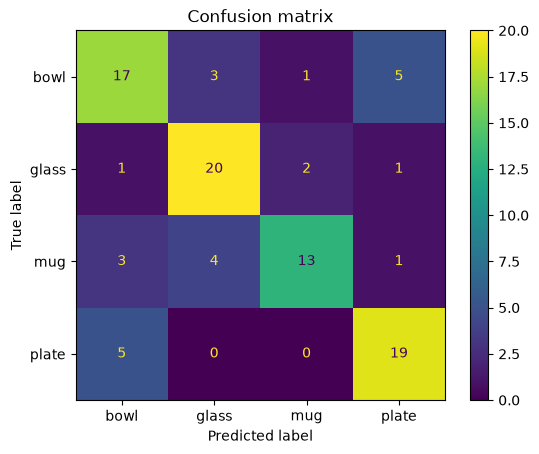

In [12]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

The classification metrics can also be calculated from the confusion matrix. The confusion matrix also shows why some classes have lower or higher precision and recall scores. The matrix shows the predcited and true labels for each input image. The model seems to predict some images depicting mugs as bowls and drinking glasses explaining the low recall score. Similarily the model seems to make a lot of predictions for the bowl class on images that are actually depicting plates and mugs which decreases precision score. The model seems to confuse plate and bowls images as also some plates are mistakingly identified as bowls.

The following code shuffles the images in the test dataset by first unbatching them and after shuffling batching them again. After obtaining the predictions, the images are displayed with their correct class labels and the probability distributions. This way the results and the performance of the model can be analysed more.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step


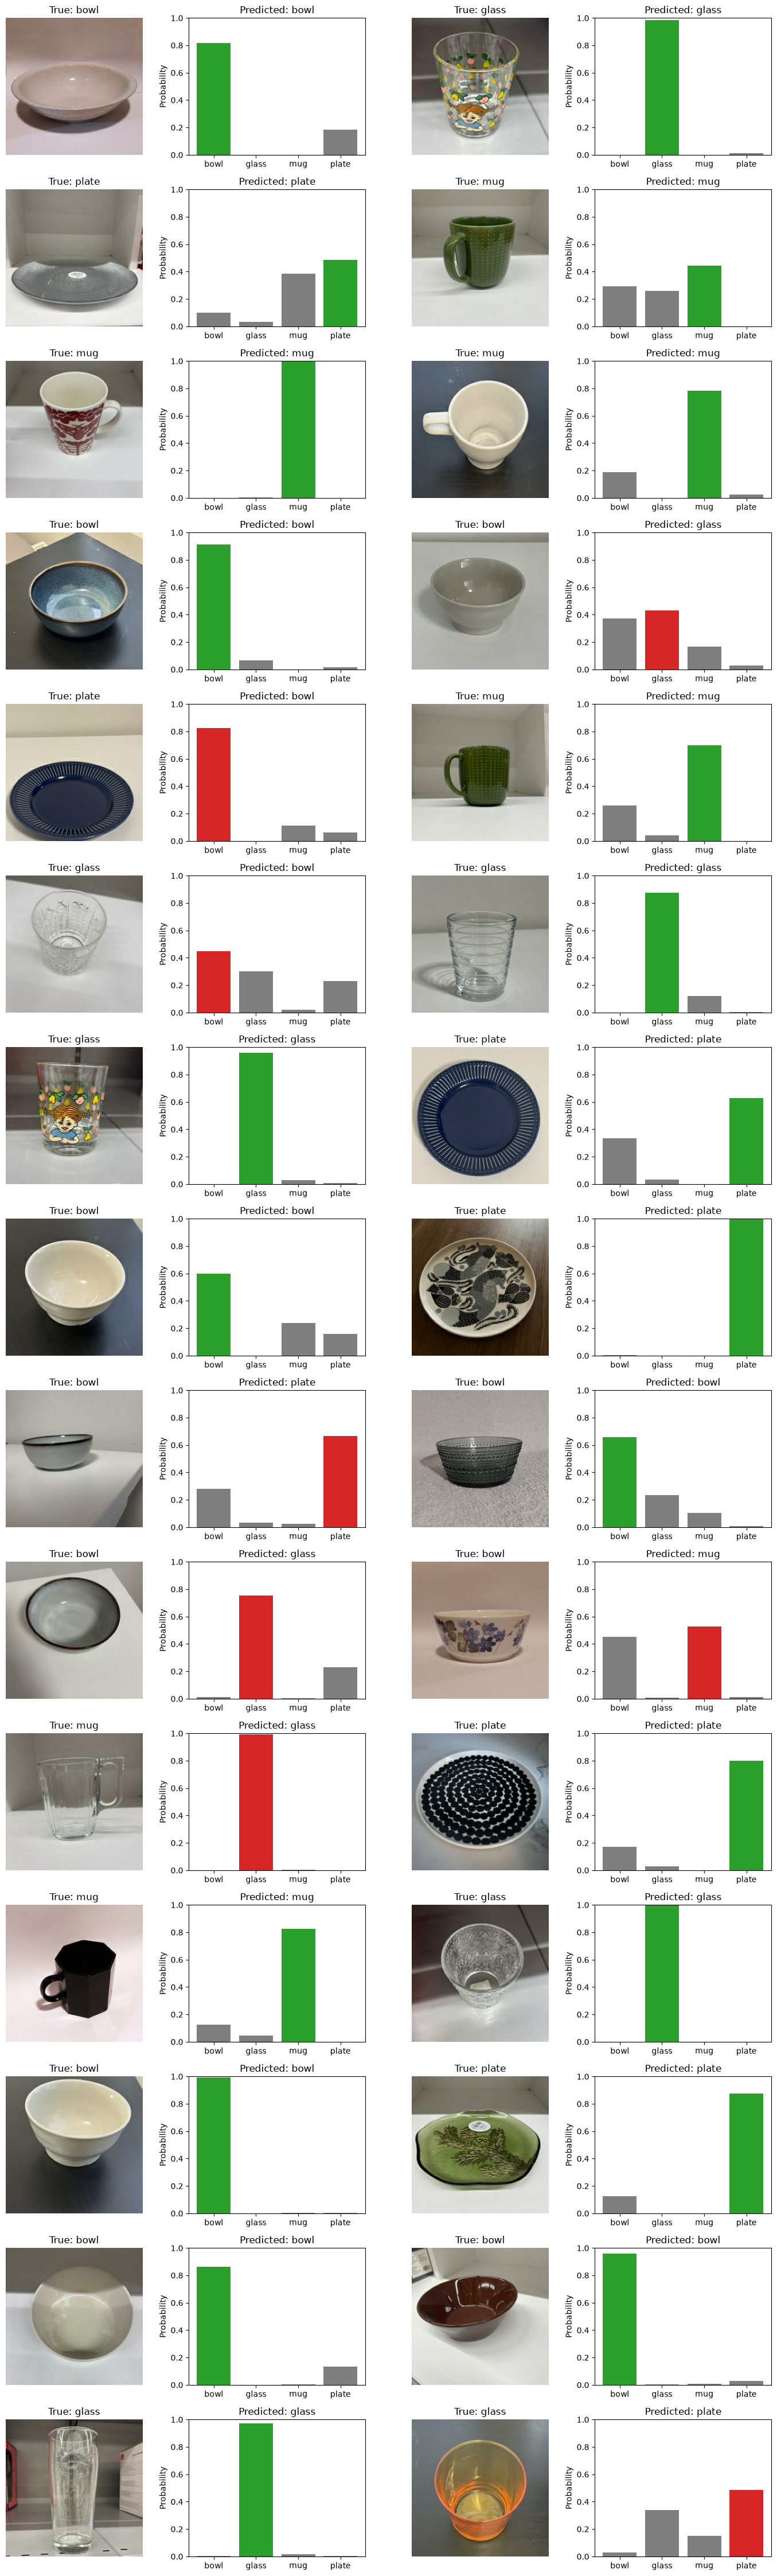

In [13]:
start = 0
images_n = 30
rows = images_n // 2

x, y = next(iter(test_dataset.unbatch().shuffle(1000).batch(images_n)))
probs = test_model.predict(x)

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

Since the items in the images have very similar shapes when photographed from above it is understandable that the model confuses them. At the same time it is hard to decipher why the model has made certain predictions. 

For example the two images of the same blue plate taken from a slightly different angles have a totally different predcition. One is confidently predicted correctly as a plate while the other is predicted as a bowl. The only difference is the angle and the horizontal colour change in the background. Could this clear line in the background have confused the model?

Another example is the three pictures of the same bluish gray bowl all with different predictions. The one with a darker background with more vibrant colours was identified correctly. The one that was photographed from the side is identified as plate eventhough the shape of the bowl is quite clear, and the third bowl photographed from above is predicted as a glass. Could the model be making prediction based more on the colour of the object instead of the actual shape of the object? 

Mugs are predicted correctly if the handle is noticeable and distinct. If the handle is not as distinct the model is less confident in the prediction making. The image depicting a clear glass mug seems to have confused the model, understandably so. The mug is photographed from an angle where the handle has a distinct shape, but the colour of the background combined with the clear class makes it hard to see the handle. Maybe training data should contain more similar images for a better performance. 